In [1]:
#Functions for getting relevant data:
#Imports
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3 as sql
from collections import defaultdict

#Count the retractions per coutry
def country_count():
    # Connect to the SQLite database
    db_path = "retractions.db"
    conn = sql.connect(db_path)

    # Load data from database table
    table_name = "retractions"
    query = "SELECT * FROM retractions"
    data = pd.read_sql_query(query, conn)
    conn.close()
        
    # Process country counts
    if 'Country' in data.columns:
        country_counts = (
            data['Country']
            .dropna()
            .astype(str)
            .str.split(';')
            .explode()
            .str.strip()
            .value_counts()
        )
 
    
    # Create the merged data (same as before)
    country_counts_df = country_counts.reset_index()
    country_counts_df.columns = ['Country', 'Retraction_Count']
    return country_counts_df

#Create a list of all subjects
def query_subjects():
    DB_PATH = "retractions.db"
    TABLE_NAME = "retractions"
    SUBJECT_COL = "Subject"
    COUNTRY_COL = "Country"
    conn=sql.connect(DB_PATH)
    query= f"SELECT {SUBJECT_COL} FROM {TABLE_NAME};"
    subj_data= pd.read_sql_query(query, conn)
    conn.close()
    return subj_data
df=query_subjects

#Define subject categories
PREFIX_MAP = {
    "(B/T)":  "Business & Technology",
    "(BLS)":  "Biological & Life Sciences",
    "(CHEM)": "Chemistry",
    "(ENG)":  "Engineering",
    "(MED)":  "Medicine",
    "(PHY)":  "Physical Sciences",
    "(SOC)":  "Social Sciences"
}

#Categorise subject based on prefix at the start of every subject (eg. BIO= biology)
def classify_by_prefix(subject: str):
    subject = subject.strip()
    for prefix, category in PREFIX_MAP.items():
        if subject.startswith(prefix):
            return category
    return None

#Categorise subject by keywords within the subject line
def classify_by_keywords(subject: str):
    s = subject.lower()

    # Business & Technology
    if any(k in s for k in [
        "business", "econom", "management", "marketing",
        "computer", "informatics", "data", "technology",
        "transport", "urban", "government", "public policy",
        "international relations", "public relations"
    ]):
        return "Business & Technology"

    # Biological & Life Sciences
    if any(k in s for k in [
        "biology", "biol", "bio ", "bio-", "genetic", "genomics",
        "cell", "cancer", "neuro", "microbiol", "immun",
        "ecolog", "zool", "botan", "agric", "food", "nutrition",
        "toxicology", "stem cell"
    ]):
        return "Biological & Life Sciences"

    # Chemistry
    if any(k in s for k in [
        "chemistry", "chem-", " -chem", "polymer", "organic",
        "inorganic", "nanoscience", "nanotech", "materials science",
        "analytical chemistry", "physical chemistry", "medicinal chemistry"
    ]):
        return "Chemistry"

    # Engineering
    if any(k in s for k in [
        "engineering", "aerospace", "mechanical", "electrical",
        "civil", "industrial", "nuclear", "biomedical",
        "structural", "materials engineering", "systems engineering"
    ]):
        return "Engineering"

    # Medicine
    if any(k in s for k in [
        "medicine", "medical", "clinic", "surgery", "surgeon",
        "oncology", "dermatology", "dentistry", "radiology",
        "cardiology", "hematology", "gynecology", "obstetrics",
        "pharmacology", "neurology", "neurosurgery", "endocrinology",
        "geriatrics", "urology", "pediatrics", "anesthesiology",
        "gastroenterology", "psychiatry", "pulmonology",
        "ophthalmology", "rheumatology"
    ]):
        return "Medicine"

    # Physical Sciences
    if any(k in s for k in [
        "physics", "astronomy", "astrophysics", "mathematics",
        "applied math", "statistics", "statistical"
    ]):
        return "Physical Sciences"

    # Social Sciences
    if any(k in s for k in [
        "psychology", "sociology", "criminology", "political science",
        "politics", "education", "pedagogy", "ethics", "bioethics",
        "forensic", "law", "legal", "linguistics", "philosophy",
        "military", "naval", "sexual", "marital", "sports",
        "recreation", "communications", "media studies"
    ]):
        return "Social Sciences"

    return "Other"

#Tries to categorise subject by prefix, if this doesn't work, categorises by keyword
def classify_subject(subject: str):
    cat = classify_by_prefix(subject)
    if cat is not None:
        return cat
    return classify_by_keywords(subject)
categories = []

#Define variable for the for loop
DB_PATH = "retractions.db"
TABLE_NAME = "retractions"
SUBJECT_COL = "Subject"
COUNTRY_COL = "Country"
conn=sql.connect(DB_PATH)
query= f"SELECT {SUBJECT_COL} FROM {TABLE_NAME};"
subj_data= pd.read_sql_query(query, conn)
conn.close()

#Converts any 'NaN' in our sql file to an empyty string to not break the split() function 
for subj_list in subj_data[SUBJECT_COL].fillna(""):
    subjects = [x.strip() for x in subj_list.split(";") if x.strip()]
    for s in subjects:
        categories.append(classify_subject(s))

# Convert to series and count
cat_series = pd.Series(categories, name="Category")
counts = (
    cat_series
    .value_counts()
    .reset_index()
)
counts.columns = ["Category", "Count"]

In [2]:
country_count()

,Country,Retraction_Count
0,China,25271
1,United States of America,3783
2,India,3478
3,Russia,2652
4,United States,2435
...,...,...
172,Comoros,1
173,Sint Maarten,1
174,St. Kitts & Nevis,1
175,Fiji,1


In [3]:
query_subjects()

,Subject
0,(BLS) Biology - Cancer;(BLS) Biology - Cellula...
1,(BLS) Biochemistry;(BLS) Biology - Cancer;(BLS...
2,(BLS) Biology - Cellular;(BLS) Biology - Molec...
3,(BLS) Biology - Cellular;(BLS) Biology - Molec...
4,(BLS) Biochemistry;(BLS) Biology - Cellular;(B...
...,...
50547,(BLS) Biochemistry;(HSC) Medicine - Cardiology...
50548,(BLS) Biology - Cellular;(BLS) Genetics;(BLS) ...
50549,(BLS) Biology - Cellular;(BLS) Genetics;(BLS) ...
50550,(BLS) Biology - Cancer;(BLS) Biology - Cellula...


In [4]:
print(counts)

                     Category  Count
0  Biological & Life Sciences  46059
1       Business & Technology  25714
2                    Medicine  23872
3           Physical Sciences  17589
4             Social Sciences  10458
5                       Other   6265


In [5]:
#Old (static) snakey
import sqlite3
import pandas as pd
import plotly.graph_objects as go

#Define variables
DB_PATH = "retractions.db"      
TABLE_NAME = "retractions"    
SUBJECT_COL = "Subject"       
COUNTRY_COL = "Country"       


#Load data from SQLite
conn = sqlite3.connect(DB_PATH)
query = f"SELECT {SUBJECT_COL}, {COUNTRY_COL} FROM {TABLE_NAME};"
df = pd.read_sql_query(query, conn)
conn.close()

#Catagorise subjects
PREFIX_MAP = {
    "(B/T)":  "Business & Technology",
    "(BLS)":  "Biological & Life Sciences",
    "(CHEM)": "Chemistry",
    "(ENG)":  "Engineering",
    "(MED)":  "Medicine",
    "(PHY)":  "Physical Sciences",
    "(SOC)":  "Social Sciences"
}

#Categorise prefixes
def classify_by_prefix(subject: str):
    subject = subject.strip()
    for prefix, category in PREFIX_MAP.items():
        if subject.startswith(prefix):
            return category
    return None   

#Categorise keywords
def classify_by_keywords(subject: str):
    s = subject.lower()

    # Business & Technology
    if any(k in s for k in [
        "business", "econom", "management", "marketing",
        "computer", "informatics", "data", "technology",
        "transport", "urban", "government", "public policy",
        "international relations", "public relations"
    ]):
        return "Business & Technology"

    # Biological & Life Sciences
    if any(k in s for k in [
        "biology", "biol", "bio ", "bio-", "genetic", "genomics",
        "cell", "cancer", "neuro", "microbiol", "immun",
        "ecolog", "zool", "botan", "agric", "food", "nutrition",
        "toxicology", "stem cell"
    ]):
        return "Biological & Life Sciences"

    # Chemistry
    if any(k in s for k in [
        "chemistry", "chem-", " -chem", "polymer", "organic",
        "inorganic", "nanoscience", "nanotech", "materials science",
        "analytical chemistry", "physical chemistry", "medicinal chemistry"
    ]):
        return "Chemistry"

    # Engineering
    if any(k in s for k in [
        "engineering", "aerospace", "mechanical", "electrical",
        "civil", "industrial", "nuclear", "biomedical",
        "structural", "materials engineering", "systems engineering"
    ]):
        return "Engineering"

    # Medicine
    if any(k in s for k in [
        "medicine", "medical", "clinic", "surgery", "surgeon",
        "oncology", "dermatology", "dentistry", "radiology",
        "cardiology", "hematology", "gynecology", "obstetrics",
        "pharmacology", "neurology", "neurosurgery", "endocrinology",
        "geriatrics", "urology", "pediatrics", "anesthesiology",
        "gastroenterology", "psychiatry", "pulmonology",
        "ophthalmology", "rheumatology"
    ]):
        return "Medicine"

    # Physical Sciences
    if any(k in s for k in [
        "physics", "astronomy", "astrophysics", "mathematics",
        "applied math", "statistics", "statistical"
    ]):
        return "Physical Sciences"

    # Social Sciences
    if any(k in s for k in [
        "psychology", "sociology", "criminology", "political science",
        "politics", "education", "pedagogy", "ethics", "bioethics",
        "forensic", "law", "legal", "linguistics", "philosophy",
        "military", "naval", "sexual", "marital", "sports",
        "recreation", "communications", "media studies"
    ]):
        return "Social Sciences"

    return "Other"

def classify_subject(subject: str):
    cat = classify_by_prefix(subject)
    if cat is not None:
        return cat
    return classify_by_keywords(subject)

#Categoru to country lines only (no continent lines)
rows = []

for _, row in df.iterrows():
    subj_list = str(row[SUBJECT_COL]) if pd.notna(row[SUBJECT_COL]) else ""
    country_list = str(row[COUNTRY_COL]) if pd.notna(row[COUNTRY_COL]) else ""

    subjects = [s.strip() for s in subj_list.split(";") if s.strip()]
    countries = [c.strip() for c in country_list.split(";") if c.strip()]

    for s in subjects:
        cat = classify_subject(s)
        for c in countries:
            rows.append({"Category": cat, "Country": c})

flow = pd.DataFrame(rows)

#Combined Category to Country
cat_country = (
    flow.groupby(["Category", "Country"])
        .size()
        .reset_index(name="value")
)

#Filter
min_cat_country = 5
cat_country = cat_country[cat_country["value"] >= min_cat_country]

print("Category→Country links:", len(cat_country))

#Sankey nodes

categories = sorted(cat_country["Category"].unique().tolist())
countries = sorted(cat_country["Country"].unique().tolist())

labels = categories + countries
label_to_index = {label: i for i, label in enumerate(labels)}

sources = cat_country["Category"].map(label_to_index).tolist()
targets = cat_country["Country"].map(label_to_index).tolist()
values  = cat_country["value"].tolist()

#Plot sankey
fig = go.Figure(data=[go.Sankey(
    node=dict(
        label=labels,
        pad=15,
        thickness=20
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values
    )
)])

fig.update_layout(
    title_text="Retractions: Category → Country (SQLite)",
    font_size=10
)

fig.write_html("sankey_sqlite_category_country.html", auto_open=True)
print("Saved as 'sankey_sqlite_category_country.html'")

Category→Country links: 547
Saved as 'sankey_sqlite_category_country.html'


C:\Users\dpurc\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning:

Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.



World countries sample: 0                        Fiji
1                    Tanzania
2                   W. Sahara
3                      Canada
4    United States of America
Name: NAME, dtype: object
Retraction countries sample: 0                       China
1    United States of America
2                       India
3                      Russia
4               United States
Name: Country, dtype: object


C:\Users\dpurc\AppData\Local\Temp\ipykernel_20200\2537759589.py:73: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



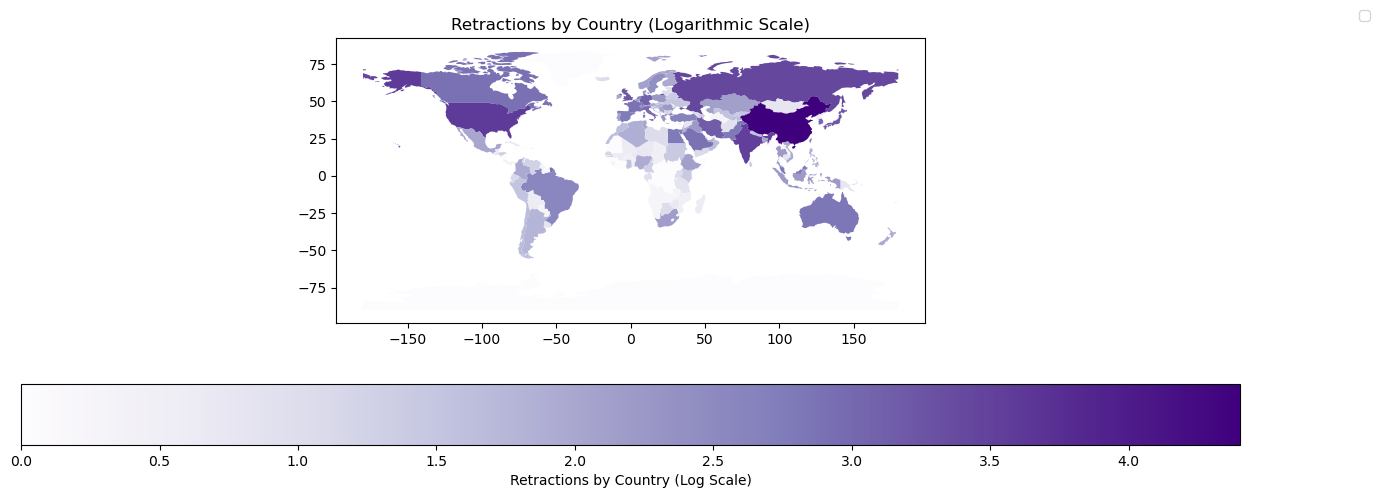

In [6]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3 as sql

url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world_gdf = gpd.read_file(url)

# Connect to the SQLite database
db_path = "retractions.db"
conn = sql.connect(db_path)

# Load data from database table
table_name = "retractions"
query = "SELECT * FROM retractions"
data = pd.read_sql_query(query, conn)
conn.close()

# Process country counts
if 'Country' in data.columns:
    country_counts = (
        data['Country']
        .dropna()
        .astype(str)
        .str.split(';')
        .explode()
        .str.strip()
        .value_counts()
    )
    
    # Convert to DataFrame for merging
    country_counts_df = country_counts.reset_index()
    country_counts_df.columns = ['Country', 'Retraction_Count']
    
    # Merge with world geometry data
    # First, let's check if country names match
    print("World countries sample:", world_gdf['NAME'].head())
    print("Retraction countries sample:", country_counts_df['Country'].head())
    

    # Create the merged data (same as before)
    country_counts_df = country_counts.reset_index()
    country_counts_df.columns = ['Country', 'Retraction_Count']
    world_merged = world_gdf.merge(
        country_counts_df, 
        left_on='NAME',  
        right_on='Country', 
        how='left'
        )

    # Apply logarithmic scale to the counts
    world_merged['Retraction_Count_Log'] = np.log10(world_merged['Retraction_Count'].fillna(0) + 1)

    fig, ax = plt.subplots(1, 1, figsize=(15, 5))
    world_merged.plot(
        column='Retraction_Count_Log',
        ax=ax,
        legend=True,
        legend_kwds={
            'label': "Retractions by Country (Log Scale)",
            'orientation': "horizontal", 
            'pad': 0.15
            },
        cmap='Purples',
        missing_kwds={
        "color": "lightgrey",
        "label": "No data"
        }
        )
    ax.set_title('Retractions by Country (Logarithmic Scale)')
    plt.tight_layout()
    fig.legend(bbox_to_anchor=(1, 1), loc='upper right')
    plt.savefig('choropleth.png')
    plt.show()

In [7]:
#Updated choropleth:
#This only works on certain computer
import sqlite3
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from ipywidgets import VBox, Output, Dropdown
import ipywidgets as widgets
import geopandas as gpd
import numpy as np

# Load world map data and retractions data
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world_gdf = gpd.read_file(url)

# Load retractions data
db_path = "retractions.db"
conn = sqlite3.connect(db_path)
data = pd.read_sql_query("SELECT * FROM retractions", conn)
conn.close()

# Process country counts and merge with world data
country_counts = (
    data['Country']
    .dropna()
    .astype(str)
    .str.split(';')
    .explode()
    .str.strip()
    .value_counts()
)

country_counts_df = country_counts.reset_index()
country_counts_df.columns = ['Country', 'Retraction_Count']
world_merged = world_gdf.merge(
    country_counts_df,
    left_on='NAME',  
    right_on='Country',
    how='left'
)

# Apply logarithmic scale
world_merged['Retraction_Count_Log'] = np.log10(world_merged['Retraction_Count'].fillna(0) + 1)

# Create main map function
def create_main_map():
    """Create the main choropleth map"""
    fig = go.Figure(go.Choroplethmapbox(
        geojson=world_merged.geometry.__geo_interface__,
        locations=world_merged.index,
        z=world_merged['Retraction_Count_Log'],
        colorscale='plasma',
        zmin=0,
        zmax=world_merged['Retraction_Count_Log'].max(),
        marker_opacity=0.7,
        marker_line_width=0,
        hoverinfo='text',
        hovertext=world_merged.apply(
            lambda row: f"<b>{row['NAME']}</b><br>Retractions: {int(row['Retraction_Count']) if pd.notna(row['Retraction_Count']) else 0}",
            axis=1
        )
    ))
   
    fig.update_layout(
        mapbox_style="carto-darkmatter",
        mapbox_zoom=1,
        mapbox_center={"lat": 20, "lon": 0},
        margin={"r":0,"t":0,"l":0,"b":0},
        height=500,
        title="World Retractions Map - Click any country to see subject distribution"
    )
   
    return fig

# Your existing classification functions
PREFIX_MAP = {
    "(B/T)": "Business & Technology",
    "(BLS)": "Biological & Life Sciences",
    "(CHEM)": "Chemistry",
    "(ENG)": "Engineering",
    "(MED)": "Medicine",
    "(PHY)": "Physical Sciences",
    "(SOC)": "Social Sciences"
}

def classify_by_prefix(s):
    for p, cat in PREFIX_MAP.items():
        if s.strip().startswith(p):
            return cat
    return None

def classify_by_keywords(s):
    s = s.lower()
    if any(k in s for k in ["business","econom","management","computer","technology"]):
        return "Business & Technology"
    if any(k in s for k in ["biology","genetic","cell","microbiol","food","nutrition"]):
        return "Biological & Life Sciences"
    if any(k in s for k in ["chem","polymer","organic","nanotech"]):
        return "Chemistry"
    if any(k in s for k in ["engineering","mechanical","electrical","civil"]):
        return "Engineering"
    if any(k in s for k in ["medic","clinic","oncology","cardiology","neurology"]):
        return "Medicine"
    if any(k in s for k in ["physics","astronomy","math"]):
        return "Physical Sciences"
    if any(k in s for k in ["psychology","sociology","criminology","political","law"]):
        return "Social Sciences"
    return "Other"

def classify_subject(s):
    return classify_by_prefix(s) or classify_by_keywords(s)

# Sankey function for specific country
def create_country_sankey(selected_country=None):
    """Create Sankey diagram filtered for a specific country"""
    if selected_country is None:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text="Click on a country in the map to see its detailed subject distribution",
            height=600,
            font_size=14
        )
        return fig
   
    conn = sqlite3.connect("retractions.db")
    df = pd.read_sql_query("SELECT Subject, Country FROM retractions;", conn)
    conn.close()
   
    mask = df['Country'].apply(lambda x: selected_country in str(x).split(';'))
    filtered_df = df[mask].copy()
   
    if len(filtered_df) == 0:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text=f"No data available for {selected_country}",
            height=600
        )
        return fig
   
    rows = []
    for _, r in filtered_df.iterrows():
        subjects = [s.strip() for s in str(r["Subject"]).split(";") if s.strip()]
        for s in subjects:
            rows.append({
                "Category": classify_subject(s),
                "Country": selected_country
            })

    flow = pd.DataFrame(rows)
    cat_country = flow.groupby(["Category", "Country"]).size().reset_index(name="value")
    cat_country = cat_country[cat_country["value"] >= 1]
   
    if len(cat_country) == 0:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text=f"No sufficient data for {selected_country}",
            height=600
        )
        return fig
   
    categories = sorted(cat_country["Category"].unique())
    countries = [selected_country]
    labels = categories + countries
    idx = {label: i for i, label in enumerate(labels)}
   
    src = cat_country["Category"].map(idx).tolist()
    tgt = cat_country["Country"].map(idx).tolist()
    val = cat_country["value"].tolist()
   
    total = sum(val) if val else 1
   
    category_colors = {
        "Business & Technology": "#1f77b4",
        "Biological & Life Sciences": "#2ca02c",
        "Chemistry": "#ff7f0e",
        "Engineering": "#9467bd",
        "Medicine": "#d62728",
        "Physical Sciences": "#8c564b",
        "Social Sciences": "#e377c2",
        "Other": "#7f7f7f"
    }
   
    country_color = "#ff6b6b"
    node_colors = [category_colors.get(lbl, "#7f7f7f") for lbl in categories] + [country_color]
   
    fig = go.Figure(data=[go.Sankey(
        arrangement="freeform",
        node=dict(
            label=labels,
            pad=20,
            thickness=25,
            color=node_colors
        ),
        link=dict(
            source=src,
            target=tgt,
            value=val,
            color="rgba(0,0,0,0.3)",
            hovertemplate=(
                "Subject: %{source.label}<br>"
                "Country: %{target.label}<br>"
                "Count: %{value}<br>"
                "<extra></extra>"
            )
        )
    )])
   
    fig.update_layout(
        title_text=f"Subject Distribution for {selected_country}",
        font_size=14,
        height=600
    )
   
    return fig

# AHHHHHHHHH PIEEEE
def create_country_pie_chart(selected_country=None):
    """Create a simple pie chart for a specific country"""
    if selected_country is None:
        fig = go.Figure()
        fig.update_layout(
            title_text="Click on a country in the map to see its subject distribution",
            height=600
        )
        fig.legend(False)
        return fig
   
    conn = sqlite3.connect("retractions.db")
    df = pd.read_sql_query("SELECT Subject, Country FROM retractions;", conn)
    conn.close()
   
    mask = df['Country'].apply(lambda x: selected_country in str(x).split(';'))
    filtered_df = df[mask].copy()
   
    if len(filtered_df) == 0:
        fig = go.Figure()
        fig.update_layout(
            title_text=f"No data available for {selected_country}",
            height=600
        )
        return fig
   
    # Classify subjects
    categories = []
    for _, row in filtered_df.iterrows():
        subjects = [s.strip() for s in str(row["Subject"]).split(";") if s.strip()]
        for subject in subjects:
            categories.append(classify_subject(subject))
   
    # Count categories
    cat_series = pd.Series(categories, name="Category")
    counts = cat_series.value_counts().reset_index()
    counts.columns = ["Category", "Count"]
   
    if len(counts) == 0:
        fig = go.Figure()
        fig.update_layout(
            title_text=f"No subject data for {selected_country}",
            height=600
        )
        return fig
   

    fig = px.pie(
        counts,
        values='Count',
        names='Category',
        title=f'Subject Distribution for {selected_country}'
    )
   
    fig.update_layout(height=600)
    return fig

# Create the main display area
display_area = Output()

# Create the map
map_fig = go.FigureWidget(create_main_map())

# Create dropdown for chart type
chart_dropdown = Dropdown(
    options=[
        ('Sankey Diagram', 'sankey'),
        ('Pie Chart', 'pie')
    ],
    value='sankey',
    description='Chart Type:',
    disabled=False,
    layout=widgets.Layout(width='200px')
)

# Create back button
back_button = widgets.Button(
    description="← Back to World Map",
    button_style='info',
    layout=widgets.Layout(width='200px', height='40px')
)

# Store the currently selected country
current_country = None

# Function to update the chart based on dropdown selection
def update_chart_display(selected_country, chart_type):
    with display_area:
        display_area.clear_output(wait=True)
        print(f"Loading {chart_type} for {selected_country}...")
       
        if chart_type == 'sankey':
            chart = create_country_sankey(selected_country)
        else:  # pie chart
            chart = create_country_pie_chart(selected_country)
       
        chart_widget = go.FigureWidget(chart)
        display(VBox([back_button, chart_dropdown, chart_widget]))

# Function to handle map clicks
def handle_map_click(trace, points, selector):
    if points.point_inds:
        idx = points.point_inds[0]
        global current_country
        current_country = world_merged.iloc[idx]['NAME']
       
        with display_area:
            display_area.clear_output(wait=True)
            update_chart_display(current_country, chart_dropdown.value)

# Function to handle dropdown changes
def handle_dropdown_change(change):
    if current_country and change['type'] == 'change' and change['name'] == 'value':
        update_chart_display(current_country, change['new'])

# Function to handle back button click
def handle_back_click(btn):
    with display_area:
        display_area.clear_output(wait=True)
        display(map_fig)

# Connect the event handlers
map_fig.data[0].on_click(handle_map_click)
chart_dropdown.observe(handle_dropdown_change)
back_button.on_click(handle_back_click)

# Initial display - show the map
with display_area:
    display(map_fig)

# Display the main interface
VBox([display_area])

In [ ]:
import sqlite3
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from ipywidgets import VBox, Output, Dropdown
import ipywidgets as widgets
import geopandas as gpd
import numpy as np

# Load world map data and retractions data
url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world_gdf = gpd.read_file(url)

# Load retractions data
db_path = "retractions.db"
conn = sqlite3.connect(db_path)
data = pd.read_sql_query("SELECT * FROM retractions", conn)
conn.close()

# Process country counts and merge with world data
country_counts = (
    data['Country']
    .dropna()
    .astype(str)
    .str.split(';')
    .explode()
    .str.strip()
    .value_counts()
)

country_counts_df = country_counts.reset_index()
country_counts_df.columns = ['Country', 'Retraction_Count']
world_merged = world_gdf.merge(
    country_counts_df,
    left_on='NAME',  
    right_on='Country',
    how='left'
)

# Apply logarithmic scale
world_merged['Retraction_Count_Log'] = np.log10(world_merged['Retraction_Count'].fillna(0) + 1)

# Create main map function
def create_main_map():
    """Create the main choropleth map"""
    fig = go.Figure(go.Choroplethmapbox(
        geojson=world_merged.geometry.__geo_interface__,
        locations=world_merged.index,
        z=world_merged['Retraction_Count_Log'],
        colorscale='plasma',
        zmin=0,
        zmax=world_merged['Retraction_Count_Log'].max(),
        marker_opacity=0.7,
        marker_line_width=0,
        hoverinfo='text',
        hovertext=world_merged.apply(
            lambda row: f"<b>{row['NAME']}</b><br>Retractions: {int(row['Retraction_Count']) if pd.notna(row['Retraction_Count']) else 0}",
            axis=1
        )
    ))
   
    fig.update_layout(
        mapbox_style="carto-darkmatter",
        mapbox_zoom=1,
        mapbox_center={"lat": 20, "lon": 0},
        margin={"r":0,"t":0,"l":0,"b":0},
        height=500,
        title="World Retractions Map - Click any country to see subject distribution"
    )
   
    return fig

# Your existing classification functions
PREFIX_MAP = {
    "(B/T)": "Business & Technology",
    "(BLS)": "Biological & Life Sciences",
    "(CHEM)": "Chemistry",
    "(ENG)": "Engineering",
    "(MED)": "Medicine",
    "(PHY)": "Physical Sciences",
    "(SOC)": "Social Sciences"
}

def classify_by_prefix(s):
    for p, cat in PREFIX_MAP.items():
        if s.strip().startswith(p):
            return cat
    return None

def classify_by_keywords(s):
    s = s.lower()
    if any(k in s for k in ["business","econom","management","computer","technology"]):
        return "Business & Technology"
    if any(k in s for k in ["biology","genetic","cell","microbiol","food","nutrition"]):
        return "Biological & Life Sciences"
    if any(k in s for k in ["chem","polymer","organic","nanotech"]):
        return "Chemistry"
    if any(k in s for k in ["engineering","mechanical","electrical","civil"]):
        return "Engineering"
    if any(k in s for k in ["medic","clinic","oncology","cardiology","neurology"]):
        return "Medicine"
    if any(k in s for k in ["physics","astronomy","math"]):
        return "Physical Sciences"
    if any(k in s for k in ["psychology","sociology","criminology","political","law"]):
        return "Social Sciences"
    return "Other"

def classify_subject(s):
    return classify_by_prefix(s) or classify_by_keywords(s)

# Sankey function for specific country
def create_country_sankey(selected_country=None):
    """Create Sankey diagram filtered for a specific country"""
    if selected_country is None:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text="Click on a country in the map to see its detailed subject distribution",
            height=600,
            font_size=14
        )
        return fig
   
    conn = sqlite3.connect("retractions.db")
    df = pd.read_sql_query("SELECT Subject, Country FROM retractions;", conn)
    conn.close()
   
    mask = df['Country'].apply(lambda x: selected_country in str(x).split(';'))
    filtered_df = df[mask].copy()
   
    if len(filtered_df) == 0:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text=f"No data available for {selected_country}",
            height=600
        )
        return fig
   
    rows = []
    for _, r in filtered_df.iterrows():
        subjects = [s.strip() for s in str(r["Subject"]).split(";") if s.strip()]
        for s in subjects:
            rows.append({
                "Category": classify_subject(s),
                "Country": selected_country
            })

    flow = pd.DataFrame(rows)
    cat_country = flow.groupby(["Category", "Country"]).size().reset_index(name="value")
    cat_country = cat_country[cat_country["value"] >= 1]
   
    if len(cat_country) == 0:
        fig = go.Figure(go.Sankey())
        fig.update_layout(
            title_text=f"No sufficient data for {selected_country}",
            height=600
        )
        return fig
   
    categories = sorted(cat_country["Category"].unique())
    countries = [selected_country]
    labels = categories + countries
    idx = {label: i for i, label in enumerate(labels)}
   
    src = cat_country["Category"].map(idx).tolist()
    tgt = cat_country["Country"].map(idx).tolist()
    val = cat_country["value"].tolist()
   
    total = sum(val) if val else 1
   
    category_colors = {
        "Business & Technology": "#1f77b4",
        "Biological & Life Sciences": "#2ca02c",
        "Chemistry": "#ff7f0e",
        "Engineering": "#9467bd",
        "Medicine": "#d62728",
        "Physical Sciences": "#8c564b",
        "Social Sciences": "#e377c2",
        "Other": "#7f7f7f"
    }
   
    country_color = "#ff6b6b"
    node_colors = [category_colors.get(lbl, "#7f7f7f") for lbl in categories] + [country_color]
   
    fig = go.Figure(data=[go.Sankey(
        arrangement="freeform",
        node=dict(
            label=labels,
            pad=20,
            thickness=25,
            color=node_colors
        ),
        link=dict(
            source=src,
            target=tgt,
            value=val,
            color="rgba(0,0,0,0.3)",
            hovertemplate=(
                "Subject: %{source.label}<br>"
                "Country: %{target.label}<br>"
                "Count: %{value}<br>"
                "<extra></extra>"
            )
        )
    )])
   
    fig.update_layout(
        title_text=f"Subject Distribution for {selected_country}",
        font_size=14,
        height=600
    )
   
    return fig

# AHHHHHHHHH PIEEEE
def create_country_pie_chart(selected_country=None):
    """Create a simple pie chart for a specific country"""
    if selected_country is None:
        fig = go.Figure()
        fig.update_layout(
            title_text="Click on a country in the map to see its subject distribution",
            height=600
        )
        fig.legend(False)
        return fig
   
    conn = sqlite3.connect("retractions.db")
    df = pd.read_sql_query("SELECT Subject, Country FROM retractions;", conn)
    conn.close()
   
    mask = df['Country'].apply(lambda x: selected_country in str(x).split(';'))
    filtered_df = df[mask].copy()
   
    if len(filtered_df) == 0:
        fig = go.Figure()
        fig.update_layout(
            title_text=f"No data available for {selected_country}",
            height=600
        )
        return fig
   
    # Classify subjects
    categories = []
    for _, row in filtered_df.iterrows():
        subjects = [s.strip() for s in str(row["Subject"]).split(";") if s.strip()]
        for subject in subjects:
            categories.append(classify_subject(subject))
   
    # Count categories
    cat_series = pd.Series(categories, name="Category")
    counts = cat_series.value_counts().reset_index()
    counts.columns = ["Category", "Count"]
   
    if len(counts) == 0:
        fig = go.Figure()
        fig.update_layout(
            title_text=f"No subject data for {selected_country}",
            height=600
        )
        return fig
   

    fig = px.pie(
        counts,
        values='Count',
        names='Category',
        title=f'Subject Distribution for {selected_country}'
    )
   
    fig.update_layout(height=600)
    return fig

# Create the main display area
display_area = Output()

# Create the map
map_fig = go.FigureWidget(create_main_map())

# Create dropdown for chart type
chart_dropdown = Dropdown(
    options=[
        ('Sankey Diagram', 'sankey'),
        ('Pie Chart', 'pie')
    ],
    value='sankey',
    description='Chart Type:',
    disabled=False,
    layout=widgets.Layout(width='200px')
)

# Create back button
back_button = widgets.Button(
    description="← Back to World Map",
    button_style='info',
    layout=widgets.Layout(width='200px', height='40px')
)

# Store the currently selected country
current_country = None

# Function to update the chart based on dropdown selection
def update_chart_display(selected_country, chart_type):
    with display_area:
        display_area.clear_output(wait=True)
        print(f"Loading {chart_type} for {selected_country}...")
       
        if chart_type == 'sankey':
            chart = create_country_sankey(selected_country)
        else:  # pie chart
            chart = create_country_pie_chart(selected_country)
       
        chart_widget = go.FigureWidget(chart)
        display(VBox([back_button, chart_dropdown, chart_widget]))

# Function to handle map clicks
def handle_map_click(trace, points, selector):
    if points.point_inds:
        idx = points.point_inds[0]
        global current_country
        current_country = world_merged.iloc[idx]['NAME']
       
        with display_area:
            display_area.clear_output(wait=True)
            update_chart_display(current_country, chart_dropdown.value)

# Function to handle dropdown changes
def handle_dropdown_change(change):
    if current_country and change['type'] == 'change' and change['name'] == 'value':
        update_chart_display(current_country, change['new'])

# Function to handle back button click
def handle_back_click(btn):
    with display_area:
        display_area.clear_output(wait=True)
        display(map_fig)

# Connect the event handlers
map_fig.data[0].on_click(handle_map_click)
chart_dropdown.observe(handle_dropdown_change)
back_button.on_click(handle_back_click)

# Initial display - show the map
with display_area:
    display(map_fig)

# Display the main interface
VBox([display_area])